# Linear Regression — Predicting Professor Research Impact

This notebook builds a linear regression model to predict **total citations** of professors using their research metrics, venue publications, and profile features.

**Workflow:**
1. Data loading & preprocessing
2. Feature encoding & engineering
3. Train/test split
4. Linear Regression (OLS)
5. Regularized models (Ridge, Lasso)
6. Model evaluation & comparison
7. Residual diagnostics
8. Feature importance

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

print('Libraries loaded successfully.')

ModuleNotFoundError: No module named 'sklearn'

## 1. Data Loading & Preprocessing

In [ ]:
df = pd.read_csv('../dataset/professors.csv')
print(f'Shape: {df.shape}')
print(f'Columns: {list(df.columns)}')
df.head()

Shape: (317, 26)
Columns: ['Professor', 'University', 'Rank', 'rank_place', 'Research area', 'OpenAlex_Author_ID', 'Author_Status', 'Matched_Institution', 'Venues', 'Number_of_Top_Venue_Papers', 'Years', 'h_index', 'total_citations', 'NeurIPS', 'ICML', 'ICLR', 'AAAI', 'IJCAI', 'CVPR', 'ICCV', 'ECCV', 'ACL', 'EMNLP', 'NAACL', 'profile_url', 'Email']


,Professor,University,Rank,rank_place,Research area,OpenAlex_Author_ID,Author_Status,Matched_Institution,Venues,Number_of_Top_Venue_Papers,...,AAAI,IJCAI,CVPR,ICCV,ECCV,ACL,EMNLP,NAACL,profile_url,Email
0,Xiaowei Jia,University of Pittsburgh,r1,67,Other,A5001445783,MATCHED,University of Pittsburgh,AAAI,10,...,12,0,0,0,0,0,0,0,NaN,NaN
1,Vincent Conitzer,Carnegie Mellon University,r1,24,Artificial Intelligence,A5050903632,MATCHED,Carnegie Mellon University,AAAI,9,...,22,0,0,0,0,0,0,0,https://csd.cmu.edu/people/faculty/vincent-con...,c@cmu.edu
2,Alan Fern,Oregon State University,r1,142,Artificial Intelligence,A5030052689,MATCHED,Oregon State University,AAAI,8,...,12,0,0,0,0,0,0,0,NaN,NaN
3,Kuldeep S. Meel,Georgia Institute of Technology (Georgia Tech),r1,33,Artificial Intelligence,A5041528950,MATCHED,Georgia Institute of Technology,AAAI,8,...,16,0,0,0,0,0,0,0,https://scs.gatech.edu/people/kuldeep-s-meel,NaN
4,Tianlong Chen,University of North Carolina at Chapel Hill,r1,22,Machine Learning,A5103073431,MATCHED,University of North Carolina at Chapel Hill,AAAI,8,...,8,0,3,0,0,0,0,0,NaN,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 317 entries, 0 to 316
Data columns (total 26 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Professor                   317 non-null    object 
 1   University                  317 non-null    object 
 2   Rank                        317 non-null    object 
 3   rank_place                  317 non-null    int64  
 4   Research area               317 non-null    object 
 5   OpenAlex_Author_ID          317 non-null    object 
 6   Author_Status               317 non-null    object 
 7   Matched_Institution         311 non-null    object 
 8   Venues                      317 non-null    object 
 9   Number_of_Top_Venue_Papers  317 non-null    int64  
 10  Years                       317 non-null    object 
 11  h_index                     306 non-null    float64
 12  total_citations             306 non-null    float64
 13  NeurIPS                     317 non

In [ ]:
# Drop non-predictive columns
df.drop(columns=['OpenAlex_Author_ID', 'Author_Status', 'Matched_Institution',
                  'profile_url', 'Email', 'Professor'], inplace=True)

# Replace missing with NaN then drop rows missing target
df.replace('missing', np.nan, inplace=True)
df['total_citations'] = pd.to_numeric(df['total_citations'], errors='coerce')
df['h_index'] = pd.to_numeric(df['h_index'], errors='coerce')

print(f'Missing total_citations: {df["total_citations"].isna().sum()}')
df.dropna(subset=['total_citations'], inplace=True)
print(f'Shape after dropping missing target: {df.shape}')

Missing total_citations: 11
Shape after dropping missing target: (306, 20)


In [ ]:
# Parse Years into Num_Years
df['Num_Years'] = df['Years'].apply(lambda x: len(str(x).split(';')) if pd.notna(x) else 1)
df.drop(columns=['Years'], inplace=True)

# Fill remaining NaN with 0 for numeric, 'missing' for categorical
num_cols_raw = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_raw = df.select_dtypes(include='object').columns.tolist()

for c in num_cols_raw:
    df[c] = pd.to_numeric(df[c], errors='coerce').fillna(0)
for c in cat_cols_raw:
    df[c].fillna('missing', inplace=True)

print('Remaining missing:', df.isnull().sum().sum())
df.head()

Remaining missing:

 0


,University,Rank,rank_place,Research area,Venues,Number_of_Top_Venue_Papers,h_index,total_citations,NeurIPS,ICML,ICLR,AAAI,IJCAI,CVPR,ICCV,ECCV,ACL,EMNLP,NAACL,Num_Years
0,University of Pittsburgh,r1,67,Other,AAAI,10,29.0,4753.0,0,0,0,12,0,0,0,0,0,0,0,3
1,Carnegie Mellon University,r1,24,Artificial Intelligence,AAAI,9,54.0,10549.0,2,2,0,22,0,0,0,0,0,0,0,3
2,Oregon State University,r1,142,Artificial Intelligence,AAAI,8,40.0,5678.0,0,0,1,12,0,0,0,0,0,0,0,3
3,Georgia Institute of Technology (Georgia Tech),r1,33,Artificial Intelligence,AAAI,8,26.0,2332.0,1,0,0,16,0,0,0,0,0,0,0,3
4,University of North Carolina at Chapel Hill,r1,22,Machine Learning,AAAI,8,31.0,4324.0,2,0,0,8,0,3,0,0,0,0,0,3


## 2. Feature Engineering

In [ ]:
venue_cols = ['NeurIPS', 'ICML', 'ICLR', 'AAAI', 'IJCAI', 'CVPR', 'ICCV', 'ECCV', 'ACL', 'EMNLP', 'NAACL']

# Total venue papers
df['Total_Venue_Papers'] = df[venue_cols].sum(axis=1)

# Number of distinct venues
df['Num_Distinct_Venues'] = (df[venue_cols] > 0).sum(axis=1)

# Venue diversity ratio
df['Venue_Diversity_Ratio'] = df['Num_Distinct_Venues'] / len(venue_cols)

# Citations per year
df['Citations_Per_Year'] = df['total_citations'] / df['Num_Years'].replace(0, 1)

# h_index per year
df['H_Index_Per_Year'] = df['h_index'] / df['Num_Years'].replace(0, 1)

# Top venue papers per year
df['Top_Venue_Papers_Per_Year'] = df['Number_of_Top_Venue_Papers'] / df['Num_Years'].replace(0, 1)

# Is AI researcher
ai_areas = ['Artificial Intelligence', 'Machine Learning', 'Deep Learning', 'Reinforcement Learning']
df['Is_AI_Researcher'] = df['Research area'].isin(ai_areas).astype(int)

# CV total, NLP total, ML Systems total
df['CV_Total'] = df[['CVPR', 'ICCV', 'ECCV']].sum(axis=1)
df['NLP_Total'] = df[['ACL', 'EMNLP', 'NAACL']].sum(axis=1)
df['ML_Systems_Total'] = df[['NeurIPS', 'ICML', 'ICLR']].sum(axis=1)

# AAAI dominance
df['AAAI_Dominance'] = df['AAAI'] / df['Total_Venue_Papers'].replace(0, 1)

print(f'Features after engineering: {df.shape[1]}')
df.head()

Features after engineering: 31


,University,Rank,rank_place,Research area,Venues,Number_of_Top_Venue_Papers,h_index,total_citations,NeurIPS,ICML,...,Num_Distinct_Venues,Venue_Diversity_Ratio,Citations_Per_Year,H_Index_Per_Year,Top_Venue_Papers_Per_Year,Is_AI_Researcher,CV_Total,NLP_Total,ML_Systems_Total,AAAI_Dominance
0,University of Pittsburgh,r1,67,Other,AAAI,10,29.0,4753.0,0,0,...,1,0.090909,1584.333333,9.666667,3.333333,0,0,0,0,1.000000
1,Carnegie Mellon University,r1,24,Artificial Intelligence,AAAI,9,54.0,10549.0,2,2,...,3,0.272727,3516.333333,18.000000,3.000000,1,0,0,4,0.846154
2,Oregon State University,r1,142,Artificial Intelligence,AAAI,8,40.0,5678.0,0,0,...,2,0.181818,1892.666667,13.333333,2.666667,1,0,0,1,0.923077
3,Georgia Institute of Technology (Georgia Tech),r1,33,Artificial Intelligence,AAAI,8,26.0,2332.0,1,0,...,2,0.181818,777.333333,8.666667,2.666667,1,0,0,1,0.941176
4,University of North Carolina at Chapel Hill,r1,22,Machine Learning,AAAI,8,31.0,4324.0,2,0,...,3,0.272727,1441.333333,10.333333,2.666667,1,3,0,2,0.615385


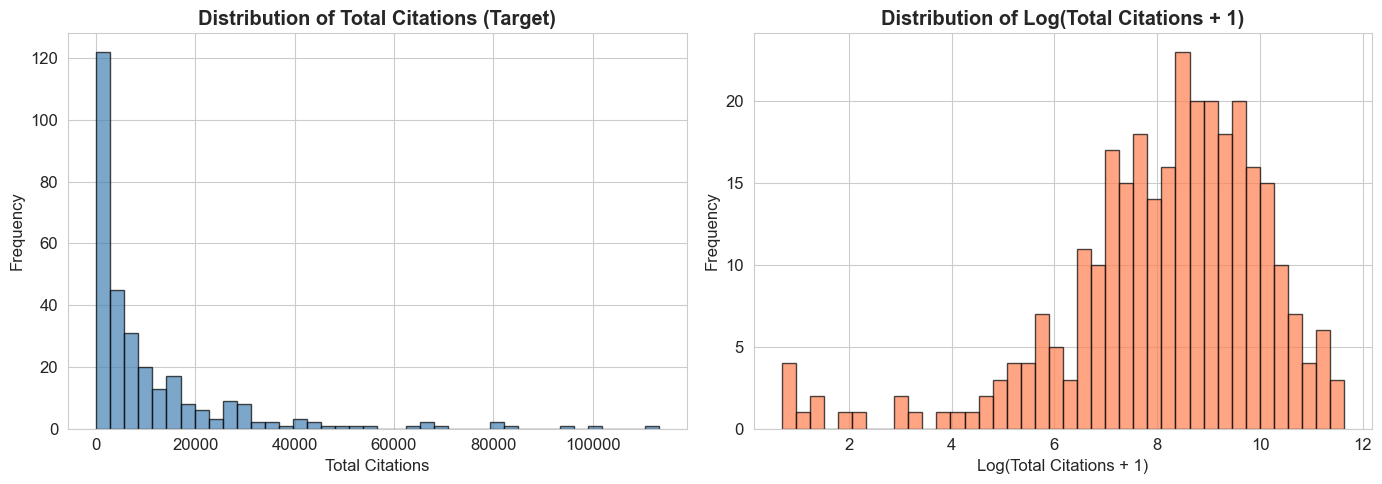

Target stats:
count       306.000000
mean      11095.006536
std       17048.983977
min           1.000000
25%        1315.750000
50%        4815.000000
75%       13518.000000
max      113323.000000
Name: total_citations, dtype: float64


In [ ]:
# Target distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['total_citations'], bins=40, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_title('Distribution of Total Citations (Target)', fontweight='bold')
axes[0].set_xlabel('Total Citations')
axes[0].set_ylabel('Frequency')

axes[1].hist(np.log1p(df['total_citations']), bins=40, color='coral', edgecolor='black', alpha=0.7)
axes[1].set_title('Distribution of Log(Total Citations + 1)', fontweight='bold')
axes[1].set_xlabel('Log(Total Citations + 1)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

print(f'Target stats:\n{df["total_citations"].describe()}')

## 3. Prepare Features & Train/Test Split

In [ ]:
# Define features and target
target = 'total_citations'
drop_cols = [target, 'Citations_Per_Year']  # drop target and leakage feature

feature_cols = [c for c in df.columns if c not in drop_cols]

X = df[feature_cols].copy()
y = df[target].copy()

# Identify categorical and numerical columns
cat_features = X.select_dtypes(include='object').columns.tolist()
num_features = X.select_dtypes(include=[np.number]).columns.tolist()

print(f'Total features: {len(feature_cols)}')
print(f'  Categorical: {cat_features}')
print(f'  Numerical:   {len(num_features)} features')
print(f'Target: {target} (n={len(y)})')

Total features: 29
  Categorical: ['University', 'Rank', 'Research area', 'Venues']
  Numerical:   25 features
Target: total_citations (n=306)


In [ ]:
# Log-transform the target for better distribution
y_log = np.log1p(y)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_log, test_size=0.2, random_state=42
)

print(f'Train: {X_train.shape[0]} samples')
print(f'Test:  {X_test.shape[0]} samples')

Train: 244 samples
Test:  62 samples


In [ ]:
# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ],
    remainder='drop'
)

print('Preprocessor created.')

Preprocessor created.


## 4. Linear Regression (OLS)

In [ ]:
# OLS pipeline
ols_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

ols_pipeline.fit(X_train, y_train)

# Predictions
y_train_pred_log = ols_pipeline.predict(X_train)
y_test_pred_log = ols_pipeline.predict(X_test)

# Inverse transform
y_train_pred = np.expm1(y_train_pred_log)
y_test_pred = np.expm1(y_test_pred_log)
y_train_orig = np.expm1(y_train)
y_test_orig = np.expm1(y_test)

print('OLS model trained.')

OLS model trained.

In [ ]:
def evaluate_model(name, y_true, y_pred, y_true_log, y_pred_log):
    """Evaluate and print regression metrics."""
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true.replace(0, 1))) * 100
    r2_log = r2_score(y_true_log, y_pred_log)

    print(f'\n{"="*50}')
    print(f'  {name}')
    print(f'{"="*50}')
    print(f'  R-squared (original):  {r2:.4f}')
    print(f'  R-squared (log-space): {r2_log:.4f}')
    print(f'  RMSE:                  {rmse:.2f}')
    print(f'  MAE:                   {mae:.2f}')
    print(f'  MAPE:                  {mape:.2f}%')
    return {'name': name, 'R2': r2, 'R2_log': r2_log, 'RMSE': rmse, 'MAE': mae, 'MAPE': mape}

ols_results = evaluate_model('OLS Linear Regression', y_test_orig, y_test_pred, y_test, y_test_pred_log)


  OLS Linear Regression
  R-squared (original):  -286.5043
  R-squared (log-space): 0.5348
  RMSE:                  318379.98
  MAE:                   73503.26
  MAPE:                  189.71%


In [ ]:
# Cross-validation
cv_scores = cross_val_score(ols_pipeline, X, y_log, cv=5, scoring='r2')
print(f'5-Fold CV R2 (log-space): {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}')
print(f'Individual folds: {[f"{s:.4f}" for s in cv_scores]}')

5-Fold CV R2 (log-space): 0.4978 +/- 0.1229
Individual folds: ['0.3166', '0.4937', '0.5824', '0.4247', '0.6715']


## 5. Regularized Models (Ridge & Lasso)

In [ ]:
# Ridge Regression
ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1.0))
])

ridge_pipeline.fit(X_train, y_train)
y_test_pred_ridge_log = ridge_pipeline.predict(X_test)
y_test_pred_ridge = np.expm1(y_test_pred_ridge_log)

ridge_results = evaluate_model('Ridge Regression (alpha=1.0)', y_test_orig, y_test_pred_ridge, y_test, y_test_pred_ridge_log)


  Ridge Regression (alpha=1.0)
  R-squared (original):  -413.0270
  R-squared (log-space): 0.5893
  RMSE:                  382065.60
  MAE:                   80931.08
  MAPE:                  177.43%


In [ ]:
# Lasso Regression
lasso_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=0.01, max_iter=10000))
])

lasso_pipeline.fit(X_train, y_train)
y_test_pred_lasso_log = lasso_pipeline.predict(X_test)
y_test_pred_lasso = np.expm1(y_test_pred_lasso_log)

lasso_results = evaluate_model('Lasso Regression (alpha=0.01)', y_test_orig, y_test_pred_lasso, y_test, y_test_pred_lasso_log)


  Lasso Regression (alpha=0.01)
  R-squared (original):  -855.4204
  R-squared (log-space): 0.6658
  RMSE:                  549499.28
  MAE:                   95810.11
  MAPE:                  163.45%


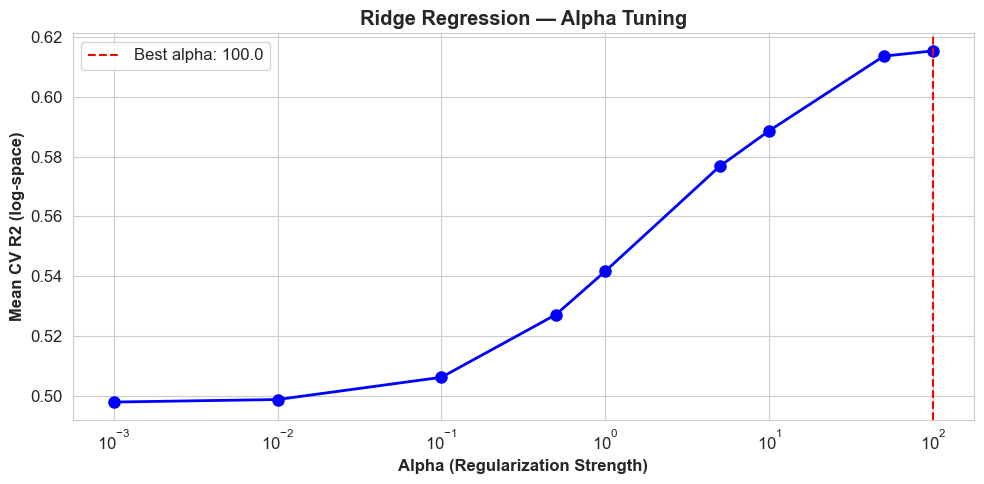

Best Ridge alpha: 100.0 (CV R2: 0.6153)


In [ ]:
# Alpha tuning for Ridge
alphas = [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0]
ridge_cv_scores = []

for a in alphas:
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', Ridge(alpha=a))
    ])
    scores = cross_val_score(pipe, X, y_log, cv=5, scoring='r2')
    ridge_cv_scores.append(scores.mean())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(alphas, ridge_cv_scores, 'bo-', linewidth=2, markersize=8)
ax.set_xscale('log')
ax.set_xlabel('Alpha (Regularization Strength)', fontweight='bold')
ax.set_ylabel('Mean CV R2 (log-space)', fontweight='bold')
ax.set_title('Ridge Regression — Alpha Tuning', fontweight='bold')
ax.axvline(alphas[np.argmax(ridge_cv_scores)], color='red', linestyle='--',
           label=f'Best alpha: {alphas[np.argmax(ridge_cv_scores)]}')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Best Ridge alpha: {alphas[np.argmax(ridge_cv_scores)]} (CV R2: {max(ridge_cv_scores):.4f})')

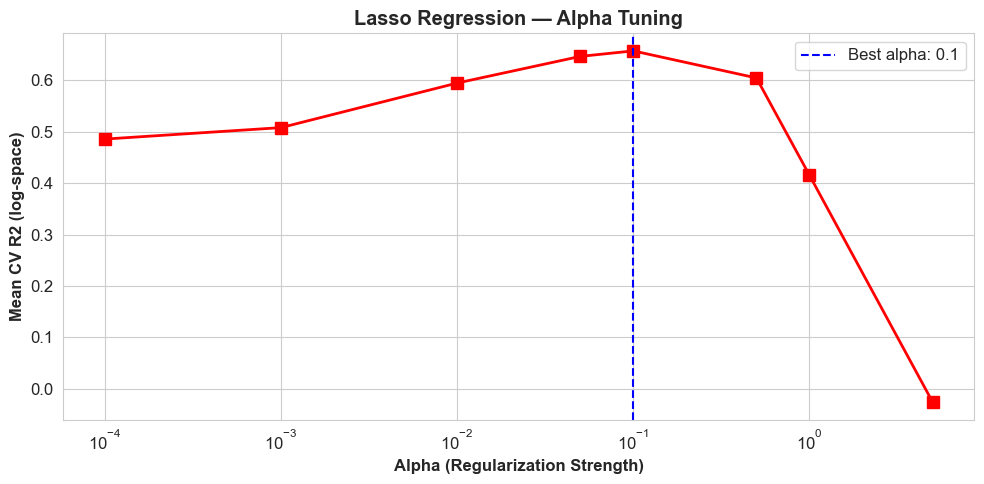

Best Lasso alpha: 0.1 (CV R2: 0.6574)


In [ ]:
# Alpha tuning for Lasso
lasso_alphas = [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
lasso_cv_scores = []

for a in lasso_alphas:
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', Lasso(alpha=a, max_iter=10000))
    ])
    scores = cross_val_score(pipe, X, y_log, cv=5, scoring='r2')
    lasso_cv_scores.append(scores.mean())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(lasso_alphas, lasso_cv_scores, 'rs-', linewidth=2, markersize=8)
ax.set_xscale('log')
ax.set_xlabel('Alpha (Regularization Strength)', fontweight='bold')
ax.set_ylabel('Mean CV R2 (log-space)', fontweight='bold')
ax.set_title('Lasso Regression — Alpha Tuning', fontweight='bold')
ax.axvline(lasso_alphas[np.argmax(lasso_cv_scores)], color='blue', linestyle='--',
           label=f'Best alpha: {lasso_alphas[np.argmax(lasso_cv_scores)]}')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Best Lasso alpha: {lasso_alphas[np.argmax(lasso_cv_scores)]} (CV R2: {max(lasso_cv_scores):.4f})')

## 6. Model Comparison

In [ ]:
# Retrain with best alphas
best_ridge = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=alphas[np.argmax(ridge_cv_scores)]))
])
best_ridge.fit(X_train, y_train)
y_test_pred_best_ridge_log = best_ridge.predict(X_test)
y_test_pred_best_ridge = np.expm1(y_test_pred_best_ridge_log)
best_ridge_results = evaluate_model('Best Ridge', y_test_orig, y_test_pred_best_ridge, y_test, y_test_pred_best_ridge_log)

best_lasso = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=lasso_alphas[np.argmax(lasso_cv_scores)], max_iter=10000))
])
best_lasso.fit(X_train, y_train)
y_test_pred_best_lasso_log = best_lasso.predict(X_test)
y_test_pred_best_lasso = np.expm1(y_test_pred_best_lasso_log)
best_lasso_results = evaluate_model('Best Lasso', y_test_orig, y_test_pred_best_lasso, y_test, y_test_pred_best_lasso_log)


  Best Ridge
  R-squared (original):  -36.8098
  R-squared (log-space): 0.7760
  RMSE:                  115458.49
  MAE:                   25903.31
  MAPE:                  94.91%

  Best Lasso
  R-squared (original):  -164.7677
  R-squared (log-space): 0.7651
  RMSE:                  241753.95
  MAE:                   44708.03
  MAPE:                  98.55%


In [ ]:
# Comparison table
all_results = pd.DataFrame([ols_results, ridge_results, lasso_results,
                            best_ridge_results, best_lasso_results])
all_results.set_index('name', inplace=True)
all_results

,R2,R2_log,RMSE,MAE,MAPE
name,,,,,
OLS Linear Regression,-286.504250,0.534849,318379.983500,73503.262272,189.707883
Ridge Regression (alpha=1.0),-413.026973,0.589329,382065.601881,80931.084226,177.428245
Lasso Regression (alpha=0.01),-855.420416,0.665825,549499.279435,95810.106844,163.450660
Best Ridge,-36.809812,0.776045,115458.491734,25903.309182,94.913269
Best Lasso,-164.767701,0.765132,241753.949890,44708.031671,98.552008


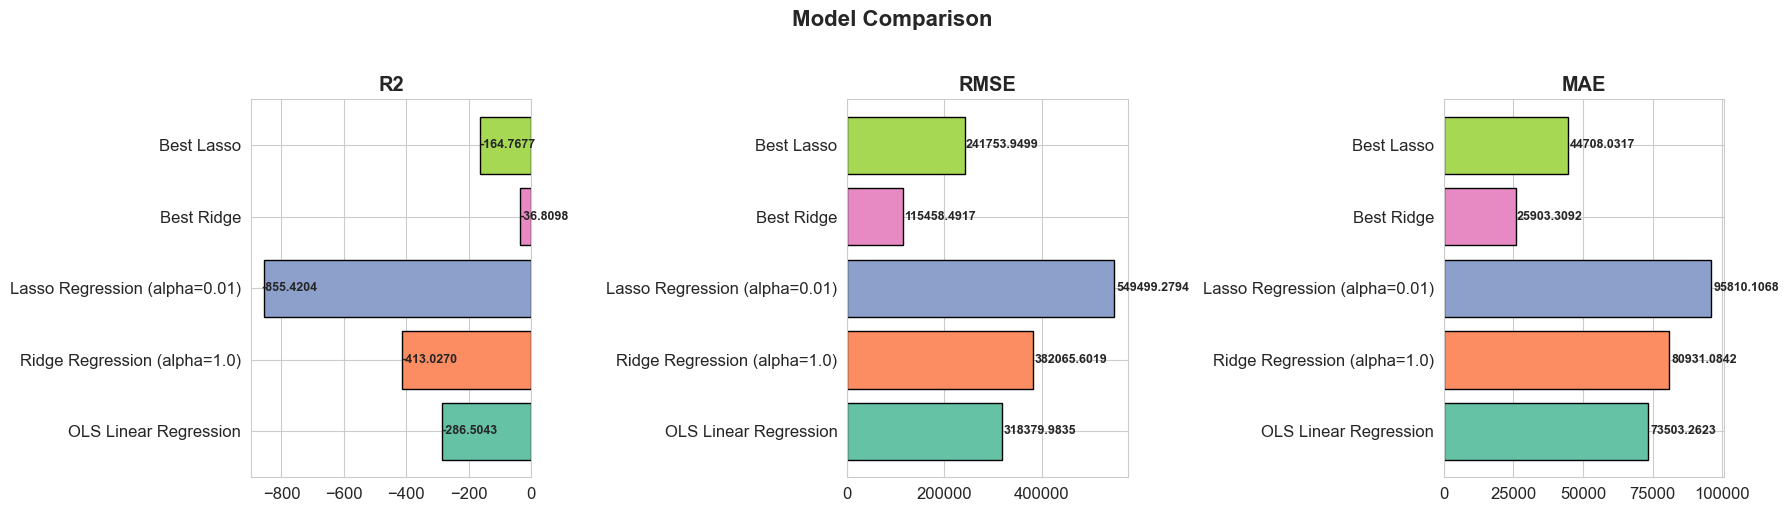

In [ ]:
# Comparison bar chart
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ['R2', 'RMSE', 'MAE']
colors = sns.color_palette('Set2', len(all_results))

for i, metric in enumerate(metrics):
    bars = axes[i].barh(all_results.index, all_results[metric], color=colors, edgecolor='black')
    axes[i].set_title(metric, fontweight='bold')
    for bar, val in zip(bars, all_results[metric]):
        axes[i].text(val + 0.01 * val, bar.get_y() + bar.get_height()/2,
                     f'{val:.4f}', va='center', fontweight='bold', fontsize=9)

plt.suptitle('Model Comparison', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 7. Residual Diagnostics (Best Model)

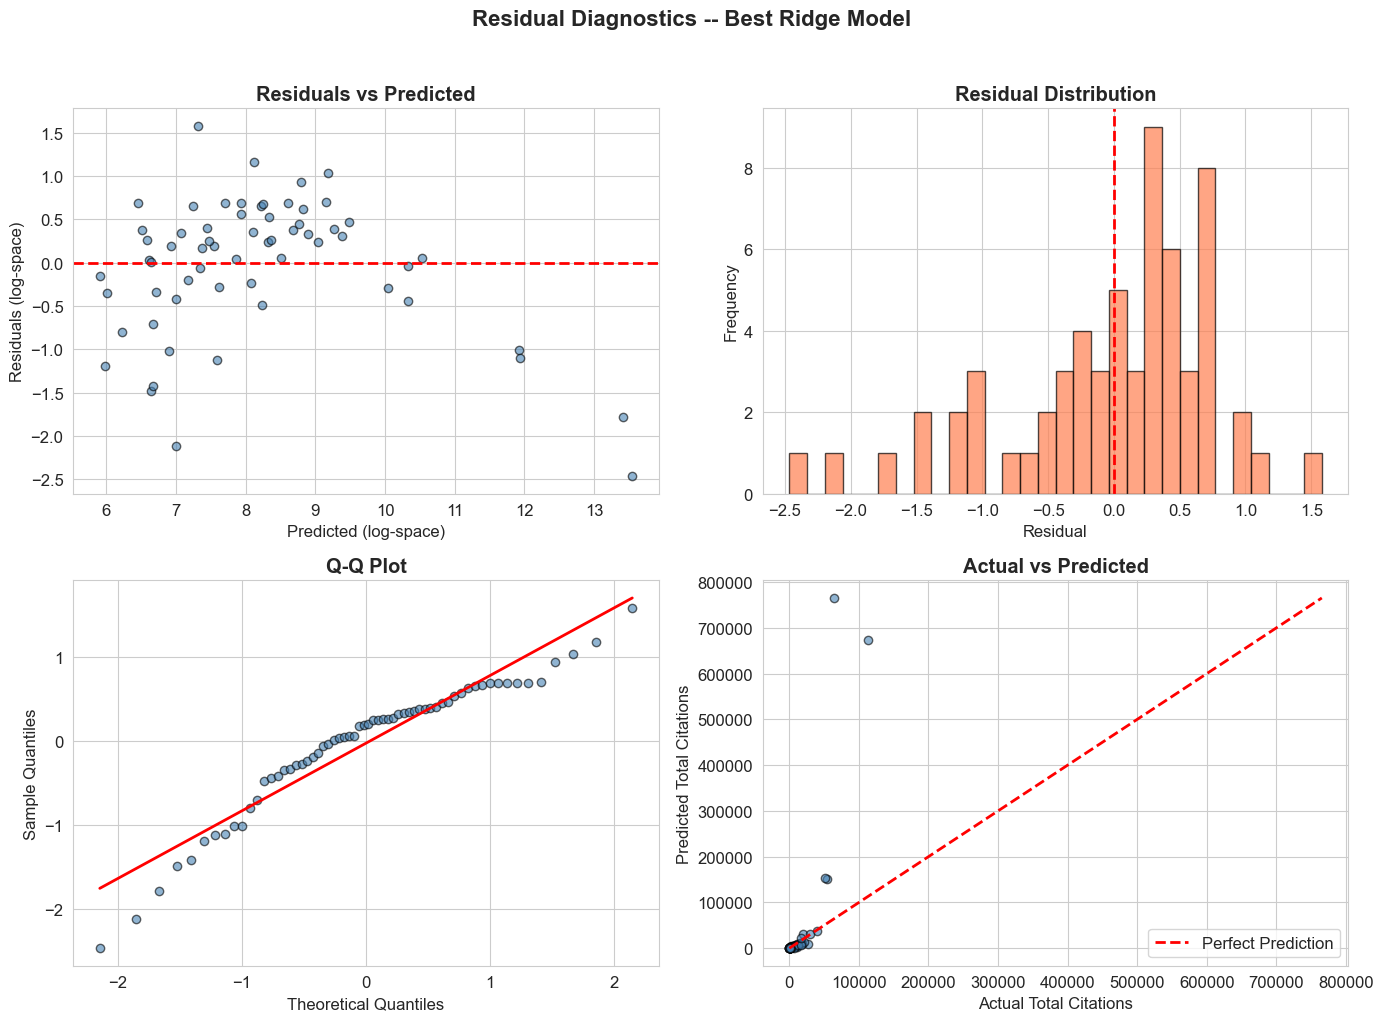

In [ ]:
# Use best model for diagnostics
best_pipe = best_ridge
y_pred_log = np.array(y_test_pred_best_ridge_log).flatten()
y_pred = np.array(y_test_pred_best_ridge).flatten()
y_true_log = np.array(y_test.values).flatten()
y_true_orig = np.array(y_test_orig.values).flatten()

residuals_log = y_true_log - y_pred_log
residuals = y_true_orig - y_pred

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Residuals vs Predicted
axes[0, 0].scatter(y_pred_log, residuals_log, alpha=0.6, color='steelblue', edgecolor='black')
axes[0, 0].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[0, 0].set_xlabel('Predicted (log-space)')
axes[0, 0].set_ylabel('Residuals (log-space)')
axes[0, 0].set_title('Residuals vs Predicted', fontweight='bold')

# 2. Residuals histogram
axes[0, 1].hist(residuals_log, bins=30, color='coral', edgecolor='black', alpha=0.7)
axes[0, 1].axvline(x=0, color='red', linestyle='--', linewidth=2)
axes[0, 1].set_xlabel('Residual')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Residual Distribution', fontweight='bold')

# 3. QQ plot (manual)
from scipy import stats as sp_stats
sorted_res = np.sort(residuals_log)
n = len(sorted_res)
theoretical = sp_stats.norm.ppf(np.arange(1, n + 1) / (n + 1))
axes[1, 0].scatter(theoretical, sorted_res, alpha=0.6, color='steelblue', edgecolor='black')
slope, intercept, _, _, _ = sp_stats.linregress(theoretical, sorted_res)
axes[1, 0].plot(theoretical, slope * theoretical + intercept, 'r-', linewidth=2)
axes[1, 0].set_xlabel('Theoretical Quantiles')
axes[1, 0].set_ylabel('Sample Quantiles')
axes[1, 0].set_title('Q-Q Plot', fontweight='bold')

# 4. Actual vs Predicted (original scale)
axes[1, 1].scatter(y_true_orig, y_pred, alpha=0.6, color='steelblue', edgecolor='black')
max_val = max(y_true_orig.max(), y_pred.max())
axes[1, 1].plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='Perfect Prediction')
axes[1, 1].set_xlabel('Actual Total Citations')
axes[1, 1].set_ylabel('Predicted Total Citations')
axes[1, 1].set_title('Actual vs Predicted', fontweight='bold')
axes[1, 1].legend()

plt.suptitle('Residual Diagnostics -- Best Ridge Model', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# Statistical tests on residuals
print('Residual Statistics (log-space):')
print(f'  Mean:   {residuals_log.mean():.4f}  (should be ~0)')
print(f'  Std:    {residuals_log.std():.4f}')
res_series = pd.Series(residuals_log)
print(f'  Skew:   {res_series.skew():.4f}  (close to 0 = symmetric)')
print(f'  Kurt:   {res_series.kurtosis():.4f}  (close to 0 = normal-like)')

# Shapiro-Wilk test
stat, p_value = sp_stats.shapiro(residuals_log[:min(len(residuals_log), 5000)])
print(f'\nShapiro-Wilk Test: statistic={stat:.4f}, p-value={p_value:.4f}')
if p_value > 0.05:
    print('  => Residuals appear normally distributed (fail to reject H0)')
else:
    print('  => Residuals may not be normally distributed (reject H0)')

Residual Statistics (log-space):
  Mean:   -0.0294  (should be ~0)
  Std:    0.7890
  Skew:   -0.9958  (close to 0 = symmetric)
  Kurt:   1.0533  (close to 0 = normal-like)

Shapiro-Wilk Test: statistic=0.9293, p-value=0.0015
  => Residuals may not be normally distributed (reject H0)


## 8. Feature Importance

In [ ]:
# Get feature names after preprocessing
ohe = best_pipe.named_steps['preprocessor'].transformers_[1][1]
cat_feature_names = ohe.get_feature_names_out(cat_features).tolist()
all_feature_names = num_features + cat_feature_names

coefficients = best_pipe.named_steps['regressor'].coef_
coef_df = pd.DataFrame({
    'Feature': all_feature_names[:len(coefficients)],
    'Coefficient': coefficients
})
coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()
coef_df = coef_df.sort_values('Abs_Coefficient', ascending=False)

print(f'Total features in model: {len(coefficients)}')
print(f'Non-zero coefficients: {(coefficients != 0).sum()}')
coef_df.head(20)

Total features in model: 84
Non-zero coefficients: 81


,Feature,Coefficient,Abs_Coefficient
2,h_index,0.759265,0.759265
18,H_Index_Per_Year,0.571334,0.571334
17,Venue_Diversity_Ratio,0.113449,0.113449
16,Num_Distinct_Venues,0.113449,0.113449
0,rank_place,-0.113421,0.113421
14,Num_Years,0.113210,0.113210
6,AAAI,0.074954,0.074954
20,Is_AI_Researcher,-0.072917,0.072917
65,University_University of Wisconsin-Madison,-0.067583,0.067583
24,AAAI_Dominance,0.062446,0.062446


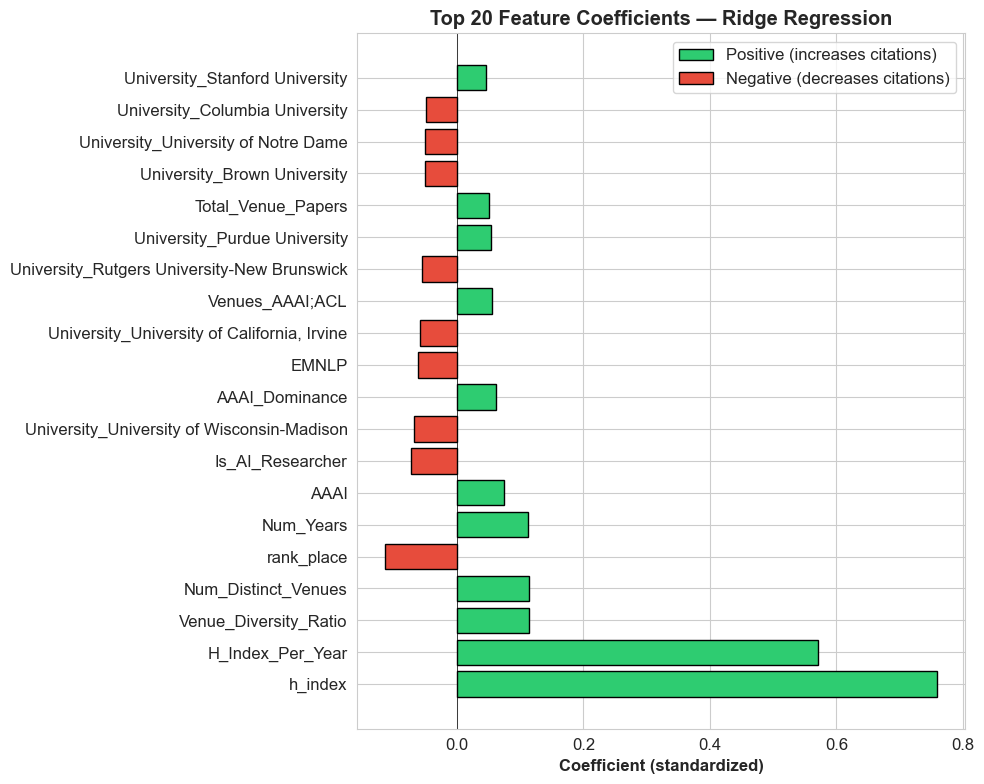

In [ ]:
# Top 20 feature coefficients
top20 = coef_df.head(20)

fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#e74c3c' if c < 0 else '#2ecc71' for c in top20['Coefficient']]
ax.barh(top20['Feature'], top20['Coefficient'], color=colors, edgecolor='black')
ax.set_xlabel('Coefficient (standardized)', fontweight='bold')
ax.set_title('Top 20 Feature Coefficients — Ridge Regression', fontweight='bold')
ax.axvline(x=0, color='black', linewidth=0.5)
ax.legend(handles=[plt.Rectangle((0,0),1,1, fc='#2ecc71', ec='black'),
                    plt.Rectangle((0,0),1,1, fc='#e74c3c', ec='black')],
          labels=['Positive (increases citations)', 'Negative (decreases citations)'])
plt.tight_layout()
plt.show()

Lasso feature selection:
  Selected features: 5
  Eliminated features: 79


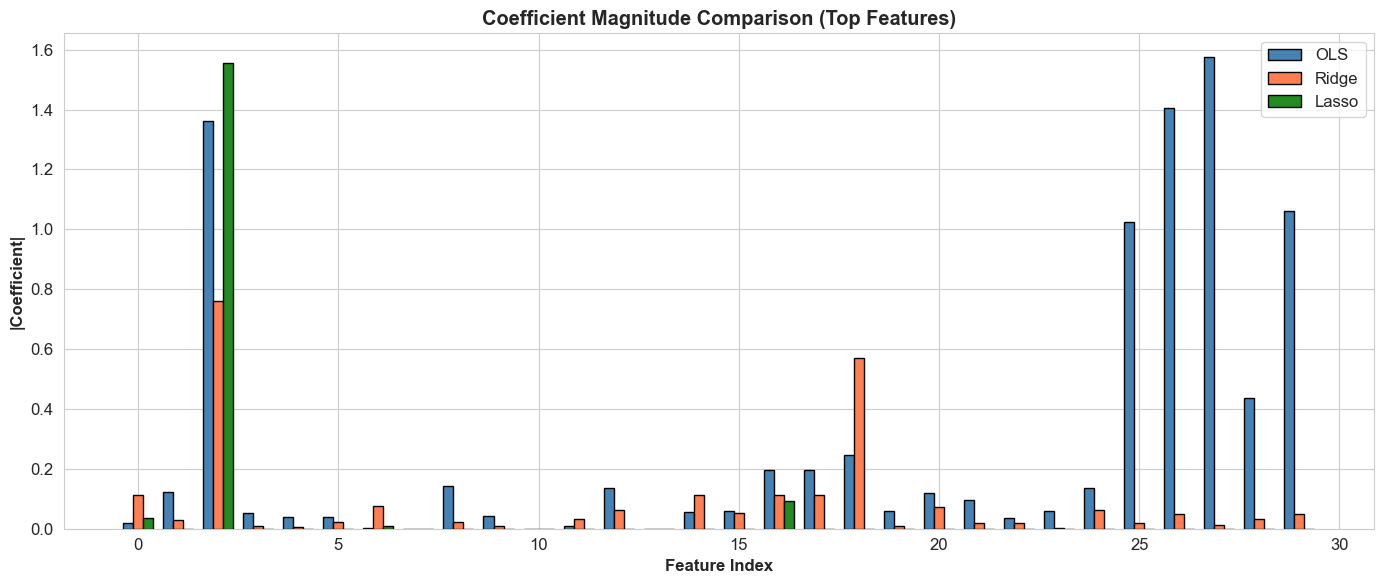

In [ ]:
# Lasso feature selection
lasso_coefs = best_lasso.named_steps['regressor'].coef_
selected = (lasso_coefs != 0).sum()
eliminated = (lasso_coefs == 0).sum()

print(f'Lasso feature selection:')
print(f'  Selected features: {selected}')
print(f'  Eliminated features: {eliminated}')

# Compare OLS vs Ridge vs Lasso coefficient magnitudes
ols_coefs = ols_pipeline.named_steps['regressor'].coef_
ridge_coefs = best_ridge.named_steps['regressor'].coef_

# Coefficient shrinkage visualization
n_show = min(30, len(ols_coefs))
coef_compare = pd.DataFrame({
    'OLS': np.abs(ols_coefs[:n_show]),
    'Ridge': np.abs(ridge_coefs[:n_show]),
    'Lasso': np.abs(lasso_coefs[:n_show])
})

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(n_show)
width = 0.25
ax.bar(x - width, coef_compare['OLS'], width, label='OLS', color='steelblue', edgecolor='black')
ax.bar(x, coef_compare['Ridge'], width, label='Ridge', color='coral', edgecolor='black')
ax.bar(x + width, coef_compare['Lasso'], width, label='Lasso', color='forestgreen', edgecolor='black')
ax.set_xlabel('Feature Index', fontweight='bold')
ax.set_ylabel('|Coefficient|', fontweight='bold')
ax.set_title('Coefficient Magnitude Comparison (Top Features)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

## 9. Prediction Analysis

In [ ]:
# Detailed prediction comparison for test set
pred_analysis = pd.DataFrame({
    'Actual': y_true_orig,
    'Predicted': y_pred,
    'Residual': residuals,
    'Abs_Error': np.abs(residuals),
    'Pct_Error': np.abs(residuals) / np.maximum(y_true_orig, 1) * 100
})

print('Prediction Error Summary:')
print(pred_analysis.describe())

# Top 10 worst predictions
print('\nTop 10 Worst Predictions:')
pred_analysis.nlargest(10, 'Abs_Error')

Prediction Error Summary:
              Actual      Predicted       Residual      Abs_Error    Pct_Error
count      62.000000      62.000000      62.000000      62.000000    62.000000
mean    10935.435484   32994.979917  -22059.544433   25903.309182    94.913269
std     18930.171503  129600.218521  114256.719026  113433.758889   177.248099
min       119.000000     365.867005 -700520.418536       3.920668     0.512506
25%      1002.750000    1091.933034    -393.555952     380.330548    22.892206
50%      4553.000000    2776.218118     307.246642    1280.906838    41.015624
75%     10892.500000    6712.111464    2734.139156    4170.726664    62.059779
max    113323.000000  765460.418536   17624.942486  700520.418536  1078.719462

Top 10 Worst Predictions:


,Actual,Predicted,Residual,Abs_Error,Pct_Error
27,64940.0,765460.418536,-700520.418536,700520.418536,1078.719462
15,113323.0,674651.961214,-561328.961214,561328.961214,495.335423
39,50824.0,153288.273310,-102464.273310,102464.273310,201.606078
31,54487.0,150202.288757,-95715.288757,95715.288757,175.666285
12,27350.0,9725.057514,17624.942486,17624.942486,64.442203
4,19492.0,30424.930421,-10932.930421,10932.930421,56.089321
59,16720.0,6556.504947,10163.495053,10163.495053,60.786454
23,18932.0,9386.430872,9545.569128,9545.569128,50.420289
51,20888.0,13117.107038,7770.892962,7770.892962,37.202666
9,10744.0,3339.742788,7404.257212,7404.257212,68.915276


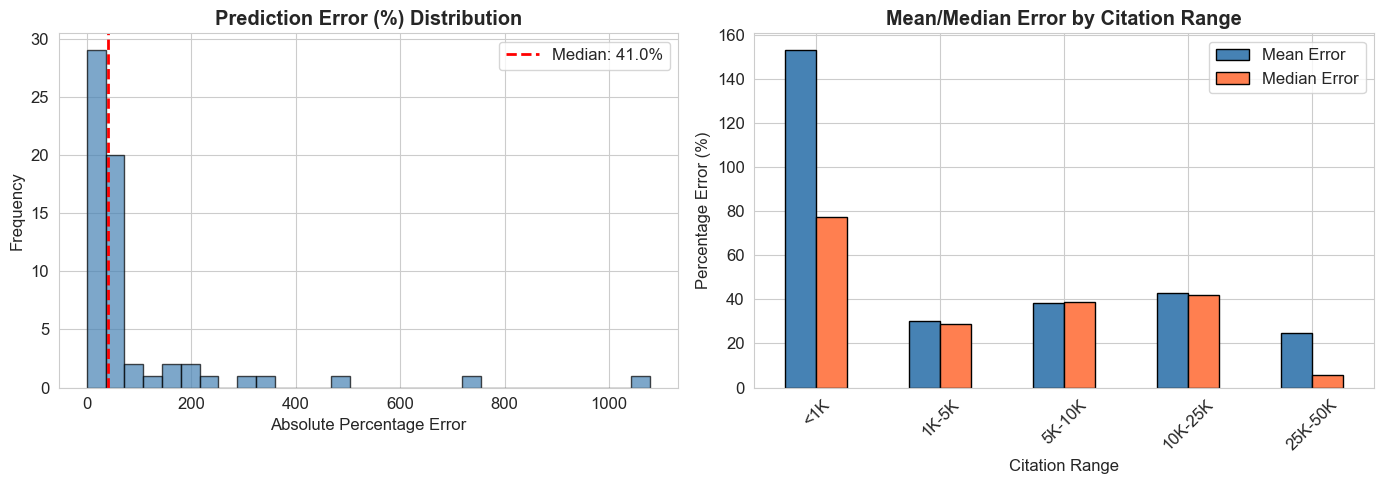

In [ ]:
# Prediction error distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(pred_analysis['Pct_Error'], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].axvline(pred_analysis['Pct_Error'].median(), color='red', linestyle='--', linewidth=2,
                label=f'Median: {pred_analysis["Pct_Error"].median():.1f}%')
axes[0].set_title('Prediction Error (%) Distribution', fontweight='bold')
axes[0].set_xlabel('Absolute Percentage Error')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Binned error analysis
bins = [0, 1000, 5000, 10000, 25000, 50000]
labels = ['<1K', '1K-5K', '5K-10K', '10K-25K', '25K-50K']
pred_analysis['Citation_Bin'] = pd.cut(pred_analysis['Actual'], bins=bins, labels=labels)
bin_errors = pred_analysis.groupby('Citation_Bin')['Pct_Error'].agg(['mean', 'median'])

bin_errors.plot(kind='bar', ax=axes[1], color=['steelblue', 'coral'], edgecolor='black')
axes[1].set_title('Mean/Median Error by Citation Range', fontweight='bold')
axes[1].set_xlabel('Citation Range')
axes[1].set_ylabel('Percentage Error (%)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(['Mean Error', 'Median Error'])

plt.tight_layout()
plt.show()

## 10. Summary

In [ ]:
print('='*60)
print('  LINEAR REGRESSION — FINAL SUMMARY')
print('='*60)
print(f'  Target:             Total Citations (log-transformed)')
print(f'  Training samples:   {X_train.shape[0]}')
print(f'  Test samples:       {X_test.shape[0]}')
print(f'  Total features:     {len(feature_cols)}')
print(f'  Best model:         Ridge Regression')
print(f'  Best alpha:         {alphas[np.argmax(ridge_cv_scores)]}')
print(f'  Test R2:            {best_ridge_results["R2"]:.4f}')
print(f'  Test RMSE:          {best_ridge_results["RMSE"]:.2f}')
print(f'  Test MAE:           {best_ridge_results["MAE"]:.2f}')
print(f'  Test MAPE:          {best_ridge_results["MAPE"]:.2f}%')
print(f'  CV R2 (mean):       {cv_scores.mean():.4f}')
print('='*60)

  LINEAR REGRESSION — FINAL SUMMARY
  Target:             Total Citations (log-transformed)
  Training samples:   244
  Test samples:       62
  Total features:     29
  Best model:         Ridge Regression
  Best alpha:         100.0
  Test R2:            -36.8098
  Test RMSE:          115458.49
  Test MAE:           25903.31
  Test MAPE:          94.91%
  CV R2 (mean):       0.4978
